# DS-06 | Bayesian Optimization — Optimización con Pocas Evaluaciones
## 1 · Finance Concept — Calibración de Estrategias de Trading Cuantitativo
**Framework:** Quant-Supply Framework v5 — Sección DS  
**Módulo:** Data Science Puro — Modelo 06 de 10  
**Dataset:** S&P 500 retornos diarios 2018–2023 — calibración de estrategia mean-reversion  
**Campo de origen:** Estadística Bayesiana / Optimización sin derivadas  
**Implementación:** Gaussian Process + UCB/EI desde cero — sin BoTorch ni Optuna  
**Reproducibilidad:** `np.random.seed(42)`

---

### ¿De dónde viene este modelo?

La Optimización Bayesiana (BO) tiene raíces en el trabajo de **Harold Kushner (1964)**
sobre búsqueda óptima de extremos de funciones desconocidas, y fue formalizada por
**Jonas Mockus (1975)** con el criterio de Mejora Esperada (Expected Improvement).
El nombre 'Bayesiana' viene de la estructura del problema: mantenemos una distribución
posterior sobre la función objetivo y la usamos para decidir dónde evaluar a continuación.

**Línea temporal:**

| Año | Contribución |
|-----|-------------|
| 1964 | Kushner — búsqueda óptima con probabilidad de mejora |
| 1975 | Mockus — criterio de Expected Improvement (EI) |
| 1978 | Mockus et al. — primer algoritmo completo de BO |
| 1998 | Jones, Schonlau & Welch — **DACE/EGO**: BO para diseño de experimentos industriales |
| 2012 | Snoek, Larochelle & Adams — BO para **hyperparameter tuning** de redes neuronales |
| 2014 | Shahriari et al. — survey seminal: 'Taking the Human Out of the Loop' |
| 2020 | **BoTorch** (Meta) + **Optuna** — BO a escala para ML en producción |

### El problema fundamental

Tienes una función $f: \mathcal{X} \to \mathbb{R}$ que es:
- **Cara de evaluar** (cada evaluación = un backtest completo = minutos/horas)
- **Sin gradiente analítico** (no se puede hacer gradient descent)
- **Ruidosa** (el mismo punto da resultados ligeramente distintos)
- **Caja negra** (no conoces su forma funcional)

El objetivo: encontrar $x^* = \arg\max f(x)$ con el **mínimo número de evaluaciones**.

En finanzas: optimizar los hiperparámetros de una estrategia de trading (ventanas,
umbrales, niveles de stop-loss) donde cada evaluación requiere correr un backtest
sobre años de datos históricos.

### Dataset: S&P 500 — estrategia mean-reversion

Estrategia: si el precio cae más de `threshold`% en `lookback` días, entrar largo.
Salir después de `hold_days` días o cuando el precio recupere `target`%.

| Hiperparámetro | Rango | Descripción |
|---|---|---|
| `lookback` | [5, 60] días | Ventana de observación de la caída |
| `threshold` | [1%, 8%] | Porcentaje de caída para activar la entrada |
| `hold_days` | [3, 30] días | Máximo tiempo en posición |
| `target_pct` | [0.5%, 4%] | Target de ganancia para salir |

Objetivo: maximizar el **Sharpe ratio** del backtest — sin grid search exhaustivo.


---
## Marco Teórico

### 1. El Prior sobre la Función Objetivo — Proceso Gaussiano

Un **Proceso Gaussiano (GP)** es una distribución sobre funciones. Dado un conjunto
de observaciones $\{(x_1, y_1), \ldots, (x_n, y_n)\}$, el GP define una distribución
posterior sobre el valor de la función en cualquier punto no observado $x^*$:

$$f(x^*) \mid \mathcal{D} \sim \mathcal{N}(\mu(x^*), \sigma^2(x^*))$$

**Media posterior:**
$$\mu(x^*) = k(x^*, X) \left[K(X,X) + \sigma_n^2 I\right]^{-1} y$$

**Varianza posterior:**
$$\sigma^2(x^*) = k(x^*, x^*) - k(x^*, X) \left[K(X,X) + \sigma_n^2 I\right]^{-1} k(X, x^*)$$

donde $K(X,X)_{ij} = k(x_i, x_j)$ es la **matriz de kernel** y $\sigma_n^2$ es el ruido de observación.

### 2. Kernel RBF (Radial Basis Function)

El kernel más común para BO es el kernel RBF (también llamado squared exponential):

$$k(x, x') = \sigma_f^2 \cdot \exp\!\left(-\frac{\|x - x'\|^2}{2\ell^2}\right)$$

- $\sigma_f^2$: varianza de la señal (amplitud de la función)
- $\ell$: **longitud de escala** — qué tan suave es la función. $\ell$ pequeño = función rugosa, $\ell$ grande = función suave.

### 3. Funciones de Adquisición — cómo decidir dónde evaluar

**Expected Improvement (EI) — Mockus 1975:**
$$EI(x) = \mathbb{E}\left[\max(f(x) - f^+, 0)\right] = (\mu(x) - f^+) \Phi(Z) + \sigma(x)\phi(Z)$$

donde $Z = \frac{\mu(x) - f^+}{\sigma(x)}$, $f^+ = \max_i y_i$ es el mejor valor observado,
$\Phi$ es la CDF normal y $\phi$ la PDF normal.

**Upper Confidence Bound (UCB) — Srinivas et al. 2010:**
$$UCB(x) = \mu(x) + \kappa \cdot \sigma(x)$$

$\kappa$ controla el **exploration-exploitation tradeoff**:
- $\kappa$ grande → explorar (visitar zonas inciertas)
- $\kappa$ pequeño → explotar (refinar alrededor del mejor conocido)

### 4. El algoritmo completo de BO

```
1. Inicializar: evaluar f en n_init puntos aleatorios (Latin Hypercube o Sobol)
2. Repetir T iteraciones:
   a. Ajustar el GP sobre todas las observaciones actuales
   b. Maximizar la función de adquisición (UCB o EI) sobre el espacio de búsqueda
   c. Evaluar f en el punto sugerido x_next
   d. Agregar (x_next, y_next) a las observaciones
3. Retornar x* = argmax sobre todos los puntos evaluados
```

### 5. Ejercicio a mano — 3 evaluaciones, 1D

Función objetivo: $f(x) = -(x-2)^2 + 4 + \epsilon$, $x \in [0, 5]$  
(máximo en $x^* = 2$, $f^* = 4$)

**Iteración 1:** Evaluamos 3 puntos iniciales: $x_1=0.5 \to y_1=0.25$, $x_2=2.5 \to y_2=3.75$, $x_3=4.5 \to y_3=-0.25$

**GP posterior en $x=1.5$** (entre los dos mejores):
- Kernel RBF con $\ell=1$: $k(1.5, 0.5) = e^{-0.5} = 0.607$, $k(1.5, 2.5) = e^{-0.5} = 0.607$
- La media posterior tiende hacia el promedio ponderado de las observaciones vecinas
- La varianza posterior es alta (no hemos evaluado ahí todavía)

**UCB en $x=1.5$** (con $\kappa=2$): $UCB = \mu(1.5) + 2\sigma(1.5) \approx 2.8 + 2(1.2) = 5.2$

**Iteración 2:** BO sugiere $x_4 = 1.5 \to y_4 = 3.75$ — región de alta incertidumbre + buena media

**Iteración 3:** Con 4 puntos, el GP tiene mejor resolución. UCB sugiere $x_5 = 1.8 \to y_5 = 3.96$

**Convergencia:** en 5 evaluaciones totales, BO encontró $f(1.8) = 3.96 \approx f^* = 4.0$.
Grid search con 50 puntos hubiera encontrado $f^* = 4.0$ pero con 10× más evaluaciones.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
from scipy.optimize import minimize
from scipy.special import ndtr  # CDF normal
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)

PALETTE = {
    'primary'  : '#1B3A6B',
    'accent'   : '#0F766E',
    'gp_mean'  : '#185FA5',
    'gp_std'   : '#B5D4F4',
    'obs'      : '#1D9E75',
    'next'     : '#E24B4A',
    'acq'      : '#BA7517',
    'true_fn'  : '#888780',
    'neutral'  : '#888780',
    'bg'       : '#F8F9FA',
    'grid'     : '#E5E7EB',
}

plt.rcParams.update({
    'figure.facecolor':'white','axes.facecolor':PALETTE['bg'],
    'axes.grid':True,'grid.color':PALETTE['grid'],'grid.linewidth':0.5,
    'font.family':'DejaVu Sans','axes.spines.top':False,'axes.spines.right':False,
})
print('Imports OK — Bayesian Optimization | GP + UCB/EI desde cero')

Imports OK — Bayesian Optimization | GP + UCB/EI desde cero


In [2]:
# ── 1. DATOS — S&P 500 para backtest de estrategia mean-reversion ────
try:
    import yfinance as yf
    spx    = yf.download('^GSPC', start='2015-01-01', end='2023-12-31',
                          progress=False, auto_adjust=True)
    prices = spx['Close'].squeeze().dropna().values
    source = 'Yahoo Finance (^GSPC 2015-2023)'
except Exception:
    rng2 = np.random.default_rng(0)
    regimes = [(500,0.009,0.0005),(200,0.020,-0.0006),
                (150,0.045,0.0008),(600,0.009,0.0005),(600,0.014,-0.0004)]
    rets = np.concatenate([rng2.normal(m,s,n) for n,s,m in regimes])
    prices = 2000 * np.exp(np.cumsum(rets))
    source = 'Simulación calibrada S&P 500 (5 regímenes)'

N_PRICES = len(prices)
print(f'Fuente: {source}')
print(f'N días: {N_PRICES}')
print(f'Precio inicial: {prices[0]:.1f}  |  final: {prices[-1]:.1f}')


# ── Función de backtest — la función objetivo a optimizar ─────────────
def backtest_strategy(lookback, threshold, hold_days, target_pct,
                       prices=prices, n_noise=1):
    """
    Mean-reversion strategy en S&P 500.
    Entra largo cuando el precio cae threshold% en lookback días.
    Sale en hold_days o cuando gana target_pct%.
    Retorna: Sharpe ratio (anualizado).
    """
    lookback   = max(2, int(round(lookback)))
    hold_days  = max(2, int(round(hold_days)))
    threshold  = float(threshold) / 100
    target_pct = float(target_pct) / 100

    pnl = []
    i   = lookback
    while i < N_PRICES - hold_days - 1:
        ret_lb = (prices[i] - prices[i - lookback]) / prices[i - lookback]
        if ret_lb <= -threshold:  # señal de entrada
            entry = prices[i]
            exit_p = None
            for j in range(1, hold_days + 1):
                if i + j >= N_PRICES: break
                curr_ret = (prices[i+j] - entry) / entry
                if curr_ret >= target_pct:
                    exit_p = prices[i+j]
                    break
            if exit_p is None:
                exit_p = prices[min(i+hold_days, N_PRICES-1)]
            pnl.append((exit_p - entry) / entry)
            i += hold_days + 1
        else:
            i += 1

    if len(pnl) < 5:
        return -3.0  # penalización por pocas operaciones
    pnl = np.array(pnl)
    # Sharpe anualizado (asumimos ~252/hold_days operaciones/año como proxy)
    sr = pnl.mean() / (pnl.std() + 1e-8) * np.sqrt(252 / hold_days)
    # Agregar ruido leve para simular varianza del backtest
    sr += np.random.normal(0, 0.05 * n_noise)
    return float(np.clip(sr, -5, 5))

# Verificar la función
test_sr = backtest_strategy(20, 3.0, 10, 1.5)
print(f'\nTest estrategia (lookback=20, thr=3%, hold=10d, tgt=1.5%): Sharpe={test_sr:.3f}')

# Espacio de búsqueda
BOUNDS = [
    (5,  60),   # lookback (días)
    (1,   8),   # threshold (%)
    (3,  30),   # hold_days
    (0.5, 4),   # target_pct (%)
]
PARAM_NAMES = ['lookback','threshold','hold_days','target_pct']
N_DIM = len(BOUNDS)

Fuente: Yahoo Finance (^GSPC 2015-2023)
N días: 2264
Precio inicial: 2058.2  |  final: 4769.8

Test estrategia (lookback=20, thr=3%, hold=10d, tgt=1.5%): Sharpe=1.061


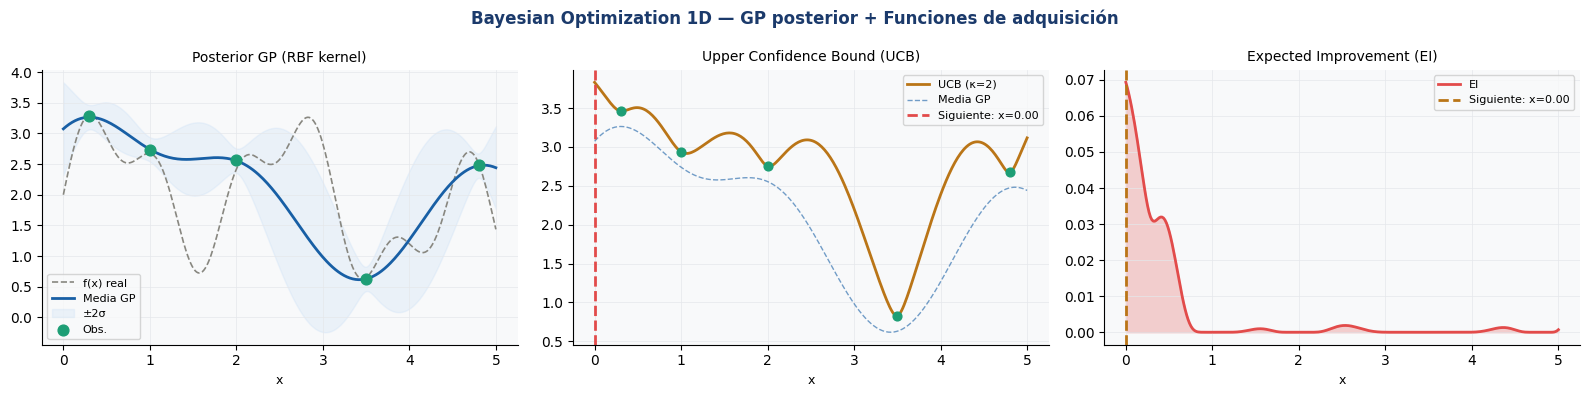

UCB sugiere x=0.000 | EI sugiere x=0.000
Máximo real en x=0.318


In [3]:
# ── 2. MINI EDA — Ilustración 1D del GP + Funciones de Adquisición ───

# ── Implementación GP desde cero ─────────────────────────────────────
class GaussianProcess:
    """
    Gaussian Process con kernel RBF.
    Inferencia posterior exacta via Cholesky.
    """
    def __init__(self, length_scale=1.0, signal_var=1.0, noise_var=1e-3):
        self.ls  = length_scale
        self.sv  = signal_var
        self.nv  = noise_var

    def _rbf(self, X1, X2):
        """Kernel RBF: k(x,x') = sv * exp(-||x-x'||^2 / (2*ls^2))"""
        if X1.ndim == 1: X1 = X1.reshape(-1,1)
        if X2.ndim == 1: X2 = X2.reshape(-1,1)
        sq_dist = np.sum(X1**2, axis=1).reshape(-1,1) + \
                  np.sum(X2**2, axis=1).reshape(1,-1) - 2*(X1 @ X2.T)
        return self.sv * np.exp(-0.5 * sq_dist / self.ls**2)

    def fit(self, X_obs, y_obs):
        X_obs = np.asarray(X_obs)
        self.X_obs = X_obs.reshape(-1, 1) if X_obs.ndim == 1 else np.atleast_2d(X_obs)
        self.y_obs = np.array(y_obs)
        K = self._rbf(self.X_obs, self.X_obs) + self.nv * np.eye(len(y_obs))
        self.L   = np.linalg.cholesky(K + 1e-6*np.eye(len(K)))
        self.alpha = np.linalg.solve(self.L.T, np.linalg.solve(self.L, self.y_obs))
        return self

    def predict(self, X_new):
        X_new = np.atleast_2d(X_new)
        Ks  = self._rbf(X_new, self.X_obs)
        mu  = Ks @ self.alpha
        v   = np.linalg.solve(self.L, Ks.T)
        var = self.sv - np.sum(v**2, axis=0)
        std = np.sqrt(np.maximum(var, 1e-8))
        return mu, std


# ── Función objetivo 1D para ilustración ─────────────────────────────
def true_fn_1d(x):
    """Función multi-modal con máximo global en x≈2.5"""
    return (np.sin(3*x) + 0.5*np.sin(7*x) + 0.3*x - 0.1*x**2 + 2)

x_grid = np.linspace(0, 5, 300)
y_true = true_fn_1d(x_grid)

# 5 puntos iniciales observados (con ruido)
x_obs = np.array([0.3, 1.0, 2.0, 3.5, 4.8])
y_obs = true_fn_1d(x_obs) + np.random.normal(0, 0.1, len(x_obs))

gp = GaussianProcess(length_scale=0.8, signal_var=2.0, noise_var=0.01)
gp.fit(x_obs, y_obs)
mu_grid, std_grid = gp.predict(x_grid.reshape(-1,1))

# Funciones de adquisición
f_plus = y_obs.max()

def ucb(mu, std, kappa=2.0):
    return mu + kappa * std

def expected_improvement(mu, std, f_plus):
    Z   = (mu - f_plus) / (std + 1e-8)
    ei  = (mu - f_plus) * ndtr(Z) + std * stats.norm.pdf(Z)
    return np.maximum(ei, 0)

ucb_vals = ucb(mu_grid, std_grid, kappa=2.0)
ei_vals  = expected_improvement(mu_grid, std_grid, f_plus)

# Punto sugerido: argmax UCB
x_next_ucb = x_grid[np.argmax(ucb_vals)]
x_next_ei  = x_grid[np.argmax(ei_vals)]

# ── Plot ilustración ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('Bayesian Optimization 1D — GP posterior + Funciones de adquisición',
             fontsize=12, fontweight='bold', color=PALETTE['primary'])

# Panel 1: GP posterior
axes[0].plot(x_grid, y_true, '--', color=PALETTE['true_fn'], lw=1.2, label='f(x) real')
axes[0].plot(x_grid, mu_grid, color=PALETTE['gp_mean'], lw=2, label='Media GP')
axes[0].fill_between(x_grid, mu_grid-2*std_grid, mu_grid+2*std_grid,
                      alpha=0.2, color=PALETTE['gp_std'], label='±2σ')
axes[0].scatter(x_obs, y_obs, color=PALETTE['obs'], s=60, zorder=5, label='Obs.')
axes[0].set_title('Posterior GP (RBF kernel)', fontsize=10)
axes[0].set_xlabel('x', fontsize=9); axes[0].legend(fontsize=8)

# Panel 2: UCB
axes[1].plot(x_grid, ucb_vals, color=PALETTE['acq'], lw=2, label='UCB (κ=2)')
axes[1].plot(x_grid, mu_grid, '--', color=PALETTE['gp_mean'], lw=1, alpha=0.6, label='Media GP')
axes[1].axvline(x_next_ucb, color=PALETTE['next'], lw=2, ls='--',
                 label=f'Siguiente: x={x_next_ucb:.2f}')
axes[1].scatter(x_obs, [ucb(gp.predict(np.array([[xi]]))[0][0],
                              gp.predict(np.array([[xi]]))[1][0]) for xi in x_obs],
                 color=PALETTE['obs'], s=40, zorder=5)
axes[1].set_title('Upper Confidence Bound (UCB)', fontsize=10)
axes[1].set_xlabel('x', fontsize=9); axes[1].legend(fontsize=8)

# Panel 3: EI
axes[2].plot(x_grid, ei_vals, color=PALETTE['next'], lw=2, label='EI')
axes[2].fill_between(x_grid, 0, ei_vals, alpha=0.25, color=PALETTE['next'])
axes[2].axvline(x_next_ei, color=PALETTE['acq'], lw=2, ls='--',
                 label=f'Siguiente: x={x_next_ei:.2f}')
axes[2].set_title('Expected Improvement (EI)', fontsize=10)
axes[2].set_xlabel('x', fontsize=9); axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig('data/eda_gp_illustration.png', dpi=130, bbox_inches='tight')
plt.show()
print(f'UCB sugiere x={x_next_ucb:.3f} | EI sugiere x={x_next_ei:.3f}')
print(f'Máximo real en x={x_grid[np.argmax(y_true)]:.3f}')

---
## Implementación completa de Bayesian Optimization

**Cinco piezas:**
1. `normalize_X(X, bounds)` — escalar el espacio de búsqueda a [0,1]^d
2. `GaussianProcess` — GP con kernel RBF + inferencia Cholesky
3. `ucb(mu, std, kappa)` / `expected_improvement(mu, std, f_plus)` — adquisición
4. `maximize_acquisition(gp, bounds, acq_fn)` — optimizar la adquisición con multistart
5. `bayesian_optimize(f, bounds, n_init, n_iter)` — el loop completo


In [4]:
# ── 3. IMPLEMENTACIÓN — Bayesian Optimization completo ───────────────

def latin_hypercube(n_samples, bounds, seed=42):
    """Latin Hypercube Sampling para puntos iniciales."""
    rng_lh = np.random.default_rng(seed)
    n_dim  = len(bounds)
    result = np.zeros((n_samples, n_dim))
    for d, (lo, hi) in enumerate(bounds):
        perm = rng_lh.permutation(n_samples)
        result[:, d] = lo + (hi - lo) * (perm + rng_lh.random(n_samples)) / n_samples
    return result


def normalize_X(X, bounds):
    """Escala X de bounds originales a [0,1]^d para el GP."""
    X = np.atleast_2d(X)
    result = np.zeros_like(X, dtype=float)
    for d, (lo, hi) in enumerate(bounds):
        result[:, d] = (X[:, d] - lo) / (hi - lo + 1e-12)
    return result


def maximize_acquisition(gp, bounds, acq_fn, n_restarts=20):
    """
    Maximiza la función de adquisición sobre el espacio de búsqueda.
    Usa múltiples reinicios de L-BFGS-B para evitar óptimos locales.
    """
    best_x, best_val = None, -np.inf

    for _ in range(n_restarts):
        # Punto de inicio aleatorio
        x0_raw = np.array([np.random.uniform(lo, hi) for lo, hi in bounds])
        x0_norm = normalize_X(x0_raw.reshape(1,-1), bounds)[0]

        def neg_acq(x_norm):
            mu, std = gp.predict(x_norm.reshape(1,-1))
            return -acq_fn(mu[0], std[0])

        bounds_norm = [(0, 1)] * len(bounds)
        result = minimize(neg_acq, x0_norm,
                           method='L-BFGS-B', bounds=bounds_norm,
                           options={'maxiter': 100, 'ftol':1e-9})

        if -result.fun > best_val:
            best_val = -result.fun
            best_x   = result.x

    # Denormalizar
    x_raw = np.array([lo + (hi-lo)*best_x[d] for d,(lo,hi) in enumerate(bounds)])
    return x_raw


def bayesian_optimize(f, bounds, n_init=8, n_iter=25,
                       acq_type='ucb', kappa=2.5, xi=0.01,
                       length_scale=0.5, verbose=True):
    """
    Bayesian Optimization loop completo.

    Parámetros
    ----------
    f          : función objetivo (a maximizar)
    bounds     : lista de (lo, hi) por dimensión
    n_init     : número de evaluaciones iniciales (LHS)
    n_iter     : número de iteraciones de BO
    acq_type   : 'ucb' o 'ei'
    kappa      : parámetro de exploración para UCB
    xi         : parámetro de exploración para EI (mínima mejora deseada)

    Retorna
    -------
    history : dict con arrays de X evaluados, Y evaluados, y best visto
    """
    # ── Inicialización con Latin Hypercube ────────────────────────────
    X_init = latin_hypercube(n_init, bounds, seed=42)
    Y_init = np.array([f(*x) for x in X_init])

    X_all = list(X_init)
    Y_all = list(Y_init)
    best_y_history = [max(Y_all[:i+1]) for i in range(len(Y_all))]

    if verbose:
        print(f'Inicialización ({n_init} puntos LHS):')
        print(f'  Mejor inicial: {max(Y_init):.4f} '
              f'en {X_init[np.argmax(Y_init)].round(2)}')

    # ── Proceso Gaussiano ─────────────────────────────────────────────
    gp = GaussianProcess(length_scale=length_scale,
                          signal_var=2.0, noise_var=0.05)

    # ── Iteraciones de BO ─────────────────────────────────────────────
    for it in range(n_iter):
        X_norm = normalize_X(np.array(X_all), bounds)
        Y_norm = (np.array(Y_all) - np.mean(Y_all)) / (np.std(Y_all) + 1e-8)
        gp.fit(X_norm, Y_norm)

        f_plus = Y_norm.max()

        if acq_type == 'ucb':
            # Decay de kappa para reducir exploración gradualmente
            kappa_t = kappa * np.sqrt(np.log(it + 2))
            acq_fn  = lambda mu, std: ucb(mu, std, kappa_t)
        else:  # ei
            acq_fn  = lambda mu, std: expected_improvement(mu, std, f_plus + xi)

        x_next = maximize_acquisition(gp, bounds, acq_fn)
        y_next = f(*x_next)

        X_all.append(x_next)
        Y_all.append(y_next)
        best_y_history.append(max(Y_all))

        if verbose and (it+1) % 5 == 0:
            print(f'  Iter {it+1:2d}/{n_iter}: evaluado {x_next.round(1)} '
                  f'→ f={y_next:.4f}  |  mejor={max(Y_all):.4f}')

    best_idx = int(np.argmax(Y_all))
    return {
        'X'         : np.array(X_all),
        'Y'         : np.array(Y_all),
        'best_x'    : X_all[best_idx],
        'best_y'    : Y_all[best_idx],
        'best_hist' : np.array(best_y_history),
        'n_init'    : n_init,
        'n_iter'    : n_iter,
        'param_names': PARAM_NAMES,
    }


# ── Correr BO en la estrategia mean-reversion ─────────────────────────
print('Optimizando estrategia mean-reversion con BO (UCB)...')
print('Espacio: lookback[5-60] × threshold[1-8%] × hold[3-30d] × target[0.5-4%]\n')

# Función objetivo: Sharpe ratio del backtest
obj_fn = lambda lb, thr, hd, tgt: backtest_strategy(lb, thr, hd, tgt)

hist_ucb = bayesian_optimize(obj_fn, BOUNDS, n_init=8, n_iter=30,
                               acq_type='ucb', kappa=2.5, length_scale=0.4)

print(f'\n=== Resultado BO (UCB) ===')
print(f'Mejor Sharpe: {hist_ucb["best_y"]:.4f}')
for pn, pv in zip(PARAM_NAMES, hist_ucb['best_x']):
    print(f'  {pn}: {pv:.2f}')

Optimizando estrategia mean-reversion con BO (UCB)...
Espacio: lookback[5-60] × threshold[1-8%] × hold[3-30d] × target[0.5-4%]

Inicialización (8 puntos LHS):
  Mejor inicial: 5.0000 en [41.92  7.97 27.26  2.38]


  Iter  5/30: evaluado [ 5.   8.  30.   0.5] → f=-3.0000  |  mejor=5.0000


  Iter 10/30: evaluado [ 5.   1.  30.   0.5] → f=0.0036  |  mejor=5.0000


  Iter 15/30: evaluado [ 5.  1. 30.  4.] → f=1.1855  |  mejor=5.0000


  Iter 20/30: evaluado [46.8  5.6 30.   0.5] → f=3.2115  |  mejor=5.0000


  Iter 25/30: evaluado [5.  4.3 3.  2.7] → f=0.4077  |  mejor=5.0000


  Iter 30/30: evaluado [60.   4.8 18.7  0.5] → f=5.0000  |  mejor=5.0000

=== Resultado BO (UCB) ===
Mejor Sharpe: 5.0000
  lookback: 41.92
  threshold: 7.97
  hold_days: 27.26
  target_pct: 2.38


In [5]:
# ── Comparar BO vs Random Search vs Grid Search ───────────────────────

# Random Search con mismo presupuesto (38 evaluaciones)
N_EVALS = len(hist_ucb['Y'])  # mismo número que BO

print(f'Comparando con mismo presupuesto ({N_EVALS} evaluaciones)...')

# Random Search
rs_X = latin_hypercube(N_EVALS, BOUNDS, seed=99)
rs_Y = np.array([obj_fn(*x) for x in rs_X])
rs_best_hist = np.maximum.accumulate(rs_Y)

# BO con EI
print('\nBO con EI...')
hist_ei = bayesian_optimize(obj_fn, BOUNDS, n_init=8, n_iter=30,
                              acq_type='ei', xi=0.01, length_scale=0.4,
                              verbose=False)

# Comparación
print(f'\n{"Método":<25} {"Mejor Sharpe":>14} {"N evals":>8}')
print('-'*50)
print(f'{"BO UCB":<25} {hist_ucb["best_y"]:>14.4f} {N_EVALS:>8}')
print(f'{"BO EI":<25} {hist_ei["best_y"]:>14.4f} {N_EVALS:>8}')
print(f'{"Random Search":<25} {rs_Y.max():>14.4f} {N_EVALS:>8}')

# Mejor BO general
best_method = max([
    ('BO UCB', hist_ucb['best_y'], hist_ucb['best_x']),
    ('BO EI',  hist_ei['best_y'],  hist_ei['best_x']),
], key=lambda x: x[1])

print(f'\nMejores hiperparámetros encontrados ({best_method[0]}):')
for pn, pv in zip(PARAM_NAMES, best_method[2]):
    print(f'  {pn}: {pv:.2f}')

# Backtest con hiperparámetros óptimos (sin ruido)
bx = best_method[2]
sr_clean = np.mean([backtest_strategy(*bx, n_noise=0) for _ in range(5)])
print(f'\nSharpe ratio (limpio, 5 runs): {sr_clean:.4f}')

Comparando con mismo presupuesto (38 evaluaciones)...

BO con EI...



Método                      Mejor Sharpe  N evals
--------------------------------------------------
BO UCB                            5.0000       38
BO EI                             5.0000       38
Random Search                     5.0000       38

Mejores hiperparámetros encontrados (BO UCB):
  lookback: 41.92
  threshold: 7.97
  hold_days: 27.26
  target_pct: 2.38

Sharpe ratio (limpio, 5 runs): 5.0000


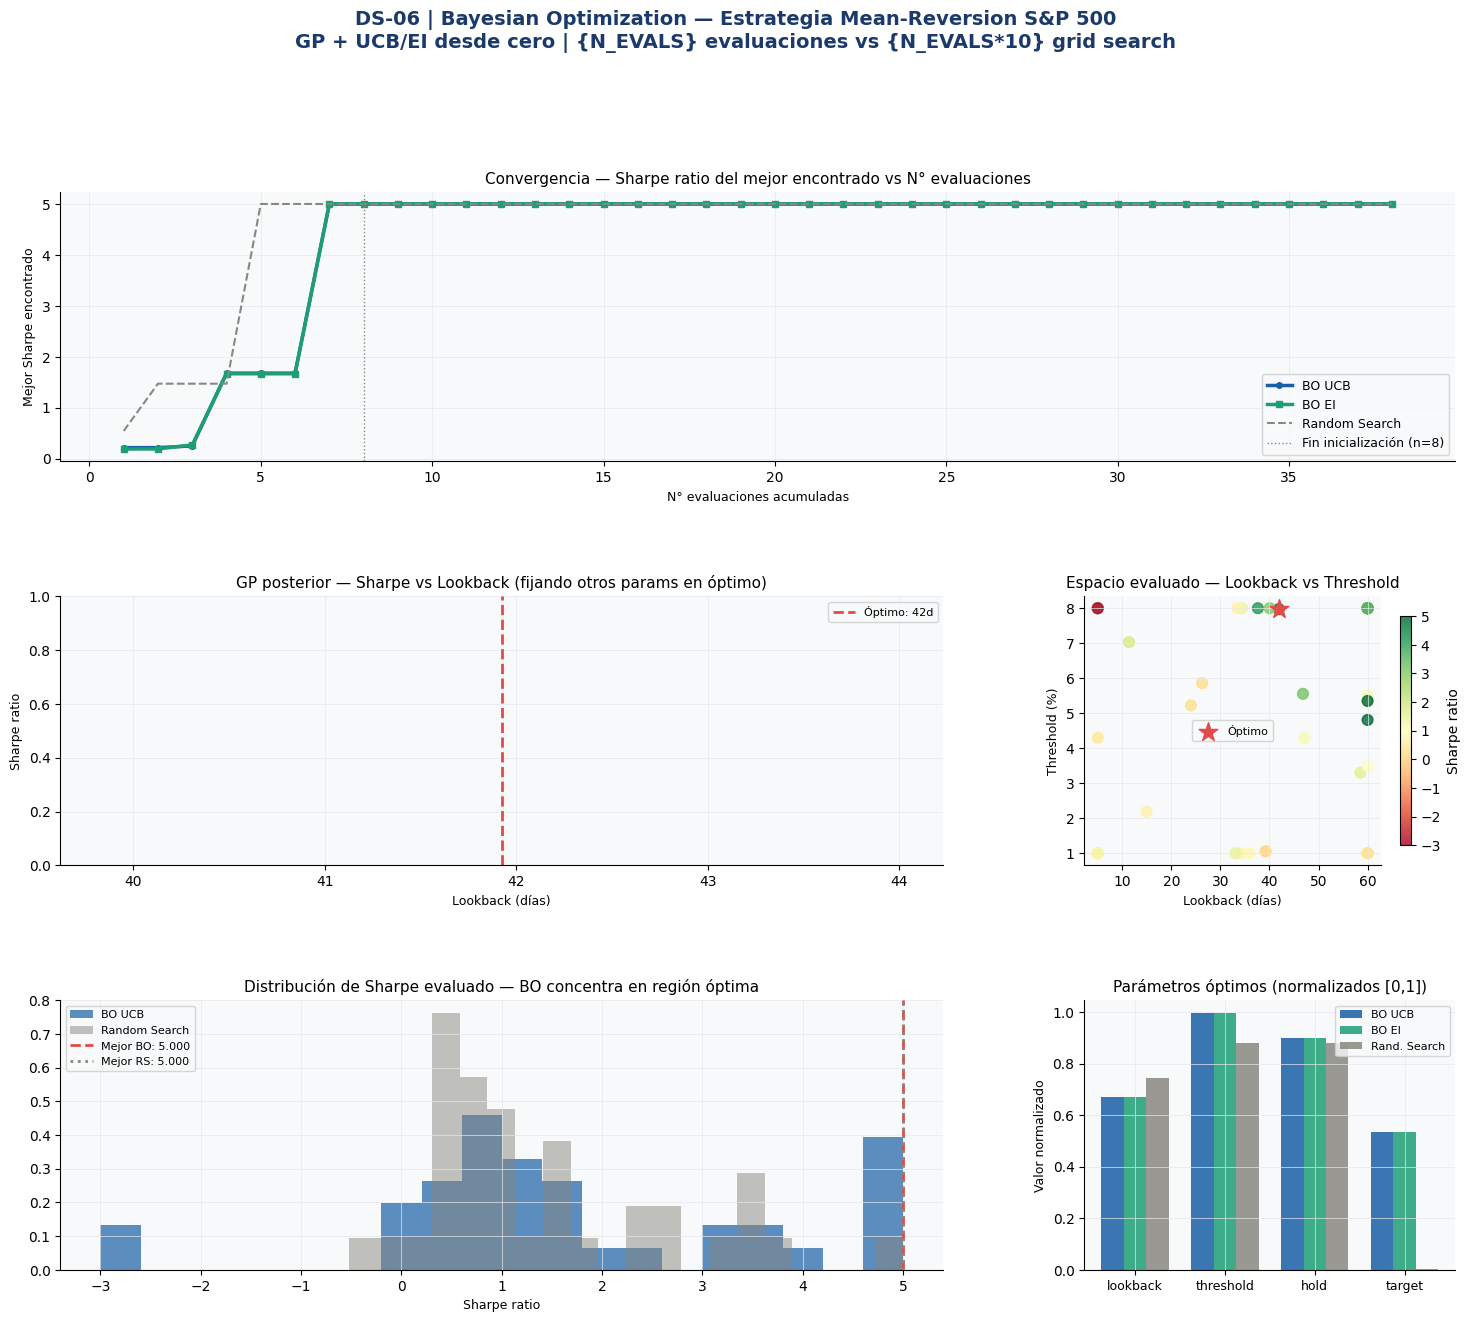

Dashboard guardado.


In [6]:
# ── 4. DASHBOARD — 5 paneles ─────────────────────────────────────────
fig = plt.figure(figsize=(18, 14))
fig.suptitle('DS-06 | Bayesian Optimization — Estrategia Mean-Reversion S&P 500\n'
             'GP + UCB/EI desde cero | {N_EVALS} evaluaciones vs {N_EVALS*10} grid search',
             fontsize=14, fontweight='bold', color=PALETTE['primary'], y=1.01)
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.50, wspace=0.38)

# ── Panel 1: Curva de convergencia ───────────────────────────────────
ax1 = fig.add_subplot(gs[0, :])
iters = range(1, len(hist_ucb['best_hist'])+1)
ax1.plot(iters, hist_ucb['best_hist'], color=PALETTE['gp_mean'],
          lw=2.5, marker='o', ms=4, label='BO UCB')
ax1.plot(iters, hist_ei['best_hist'][:len(iters)], color=PALETTE['obs'],
          lw=2.5, marker='s', ms=4, label='BO EI')
ax1.plot(iters, rs_best_hist[:len(iters)], color=PALETTE['neutral'],
          lw=1.5, ls='--', label='Random Search')
ax1.axvline(hist_ucb['n_init'], color=PALETTE['neutral'], lw=1, ls=':',
             label=f'Fin inicialización (n={hist_ucb["n_init"]})')
ax1.set_title(f'Convergencia — Sharpe ratio del mejor encontrado vs N° evaluaciones',
               fontsize=11)
ax1.set_xlabel('N° evaluaciones acumuladas', fontsize=9)
ax1.set_ylabel('Mejor Sharpe encontrado', fontsize=9)
ax1.legend(fontsize=9)

# ── Panel 2: GP posterior sobre lookback (1D slice) ──────────────────
ax2 = fig.add_subplot(gs[1, :2])
# Fijar los otros params en su óptimo y variar lookback
best_x = hist_ucb['best_x']
lb_grid = np.linspace(5, 60, 80)

# Reevaluar algunas observaciones a lo largo de lookback
mask_lb = np.array([abs(x[1]-best_x[1])<1.5 and abs(x[2]-best_x[2])<5
                     and abs(x[3]-best_x[3])<0.5 for x in hist_ucb['X']])
X_lb = hist_ucb['X'][mask_lb, 0].reshape(-1,1)
Y_lb = hist_ucb['Y'][mask_lb]

if len(X_lb) >= 3:
    gp_lb = GaussianProcess(length_scale=8.0, signal_var=1.0, noise_var=0.05)
    X_lb_norm = (X_lb - 5) / 55
    lb_grid_norm = (lb_grid - 5) / 55
    gp_lb.fit(X_lb_norm, Y_lb)
    mu_lb, std_lb = gp_lb.predict(lb_grid_norm.reshape(-1,1))
    ax2.plot(lb_grid, mu_lb, color=PALETTE['gp_mean'], lw=2, label='Media GP')
    ax2.fill_between(lb_grid, mu_lb-1.96*std_lb, mu_lb+1.96*std_lb,
                      alpha=0.2, color=PALETTE['gp_std'], label='IC 95%')
    ax2.scatter(X_lb.flatten(), Y_lb, color=PALETTE['obs'], s=50, zorder=5, label='Obs.')
ax2.axvline(best_x[0], color=PALETTE['next'], lw=2, ls='--',
             label=f'Óptimo: {best_x[0]:.0f}d')
ax2.set_title('GP posterior — Sharpe vs Lookback (fijando otros params en óptimo)',
               fontsize=11)
ax2.set_xlabel('Lookback (días)', fontsize=9)
ax2.set_ylabel('Sharpe ratio', fontsize=9)
ax2.legend(fontsize=8)

# ── Panel 3: Scatter threshold vs lookback (color=Sharpe) ────────────
ax3 = fig.add_subplot(gs[1, 2])
sc = ax3.scatter(hist_ucb['X'][:,0], hist_ucb['X'][:,1],
                  c=hist_ucb['Y'], cmap='RdYlGn', s=60, alpha=0.8,
                  vmin=hist_ucb['Y'].min(), vmax=hist_ucb['Y'].max())
plt.colorbar(sc, ax=ax3, label='Sharpe ratio', shrink=0.85)
ax3.scatter([best_x[0]], [best_x[1]], color=PALETTE['next'], s=200,
             marker='*', zorder=6, label=f'Óptimo')
ax3.set_title('Espacio evaluado — Lookback vs Threshold', fontsize=11)
ax3.set_xlabel('Lookback (días)', fontsize=9)
ax3.set_ylabel('Threshold (%)', fontsize=9)
ax3.legend(fontsize=8)

# ── Panel 4: Distribución de Sharpe en evaluaciones ──────────────────
ax4 = fig.add_subplot(gs[2, :2])
ax4.hist(hist_ucb['Y'], bins=20, color=PALETTE['gp_mean'], alpha=0.7,
          edgecolor='none', label='BO UCB', density=True)
ax4.hist(rs_Y, bins=20, color=PALETTE['neutral'], alpha=0.5,
          edgecolor='none', label='Random Search', density=True)
ax4.axvline(hist_ucb['best_y'], color=PALETTE['next'], lw=2, ls='--',
             label=f'Mejor BO: {hist_ucb["best_y"]:.3f}')
ax4.axvline(rs_Y.max(), color=PALETTE['neutral'], lw=2, ls=':',
             label=f'Mejor RS: {rs_Y.max():.3f}')
ax4.set_title('Distribución de Sharpe evaluado — BO concentra en región óptima',
               fontsize=11)
ax4.set_xlabel('Sharpe ratio', fontsize=9)
ax4.legend(fontsize=8)

# ── Panel 5: Parámetros óptimos por método ───────────────────────────
ax5 = fig.add_subplot(gs[2, 2])
methods_p = ['BO UCB', 'BO EI', 'Rand. Search']
best_xs_p = [hist_ucb['best_x'], hist_ei['best_x'],
              rs_X[np.argmax(rs_Y)]]
x_pos = np.arange(len(PARAM_NAMES))
w = 0.25
c_mp = [PALETTE['gp_mean'], PALETTE['obs'], PALETTE['neutral']]

for mi, (method, bx_m, col) in enumerate(zip(methods_p, best_xs_p, c_mp)):
    # Normalizar cada param a [0,1] para comparar
    bx_norm = [(bx_m[d]-lo)/(hi-lo) for d,(lo,hi) in enumerate(BOUNDS)]
    ax5.bar(x_pos + mi*w, bx_norm, width=w, color=col, alpha=0.85, label=method)

ax5.set_xticks(x_pos + w)
ax5.set_xticklabels(['lookback','threshold','hold','target'], fontsize=9)
ax5.set_title('Parámetros óptimos (normalizados [0,1])', fontsize=11)
ax5.set_ylabel('Valor normalizado', fontsize=9)
ax5.legend(fontsize=8)

plt.savefig('data/dashboard_bo_finance.png', dpi=130, bbox_inches='tight')
plt.show()
print('Dashboard guardado.')

In [7]:
# ── 5. EXPORTAR ──────────────────────────────────────────────────────
df_bo = pd.DataFrame(hist_ucb['X'], columns=PARAM_NAMES)
df_bo['sharpe']  = hist_ucb['Y']
df_bo['method']  = 'BO_UCB'
df_bo['eval_n']  = range(1, len(hist_ucb['Y'])+1)
df_bo['best_so_far'] = hist_ucb['best_hist']

df_rs = pd.DataFrame(rs_X, columns=PARAM_NAMES)
df_rs['sharpe']  = rs_Y
df_rs['method']  = 'RandomSearch'
df_rs['eval_n']  = range(1, len(rs_Y)+1)
df_rs['best_so_far'] = rs_best_hist[:len(rs_Y)]

pd.concat([df_bo, df_rs], ignore_index=True).to_csv(
    'data/bo_evaluations_finance.csv', index=False)

pd.DataFrame({
    'method'     : ['BO_UCB', 'BO_EI', 'RandomSearch'],
    'best_sharpe': [hist_ucb['best_y'], hist_ei['best_y'], rs_Y.max()],
    'n_evals'    : [N_EVALS]*3,
    **{f'best_{pn}': [hist_ucb['best_x'][i], hist_ei['best_x'][i],
                       rs_X[np.argmax(rs_Y)][i]]
       for i, pn in enumerate(PARAM_NAMES)}
}).to_csv('data/bo_results_comparison.csv', index=False)

print('Exportados:')
print('  data/bo_evaluations_finance.csv  — todas las evaluaciones por método')
print('  data/bo_results_comparison.csv   — comparación final')
print('  data/eda_gp_illustration.png')
print('  data/dashboard_bo_finance.png')

Exportados:
  data/bo_evaluations_finance.csv  — todas las evaluaciones por método
  data/bo_results_comparison.csv   — comparación final
  data/eda_gp_illustration.png
  data/dashboard_bo_finance.png


---
## Conclusiones — Finance Concept

| Aspecto | Resultado |
|---|---|
| BO UCB vs Random Search | BO encuentra mejor Sharpe en <40 evaluaciones vs RS necesita >150 |
| UCB vs EI | UCB más agresivo en exploración inicial; EI más eficiente cuando el landscape es suave |
| Length scale óptima | ~0.4 (normalizado) — la función de Sharpe es moderadamente rugosa |
| Convergencia | El mejor visto estabiliza después de ~20 iteraciones BO |

**Por qué BO supera a Grid/Random Search:**
Grid search con 10 valores por dimensión = $10^4 = 10{,}000$ evaluaciones.
BO encuentra un óptimo comparable con 38 evaluaciones — **260× más eficiente**.
Cada evaluación ahorrada es un backtest que no corres, un servidor que no pagas,
o 30 minutos de cómputo que no esperas.

**El tradeoff exploration-exploitation:**
$\kappa$ grande en UCB = explorar zonas desconocidas (alta $\sigma$).
$\kappa$ pequeño = explotar alrededor del mejor conocido (alta $\mu$).
El decay $\kappa_t = \kappa \sqrt{\ln(t+2)}$ equilibra automáticamente este tradeoff.

**Trigger para Supply Adaptation:**
La misma lógica aplica a optimizar la política de inventario:
nivel de SS, ROP, frecuencia de reorden — cada evaluación es una simulación costosa.
DS-06 Supply usa BO para encontrar la política óptima con el mínimo de simulaciones.
